# Irmak - Random Forest
Run all cells in order and save the notebook to retain its tables and plots.
Each experiment uses 15 complete forests of 200 trees. Matching model numbers
use the same randomly sampled hyperparameters.

Use the partitions returned by `src.data_split.main()` directly:

| Experiment | Train | Validation | Test | Model selection / threshold |
|---|---|---|---|---|
| Random | Existing 70% train | Existing 15% validation | Existing 15% test | Train-only 5-fold CV PR-AUC with 1-SE selection; validation F1 threshold tuning |
| Temporal | All 2015-2016 | None | All 2017 | Report all 15 models at fixed threshold 0.5; no tuning or winner selection |

No extra temporal validation partition or temporal refitting stage is created.
Random test scores evaluate its train-CV-selected model. Temporal test scores
are descriptive results for the predefined configurations, not validation scores
for choosing or tuning a model.

Each execution saves one combined numbered CSV (`model_results_2.csv`,
`model_results_3.csv`, and so on) under `results/irmak_randomForest`.
Existing CSVs are preserved. Hyperparameters, split summaries, diagnostic tables
and plots remain in the notebook. Section 8 also exports seven comparison PNGs
with the CSV run number in their filenames. Existing result CSVs are preserved.
Hyperparameters appear in Section 1. The final train/validation F1-gap
summary applies only to random, since temporal has no validation set.


In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, average_precision_score
from sklearn.model_selection import ParameterSampler, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

def find_project_root(start_directory):
    """Find the repository from its root or notebooks directory."""
    for directory in (start_directory, *start_directory.parents):
        if (directory / "src/data_split.py").is_file():
            return directory
    raise FileNotFoundError("Open this notebook inside the hotel-cancellation repository.")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_split import main as create_data_splits, split_features_target
from src.evaluation import evaluate, RESULTS_DIR
from src.irmak_randomForest import aggregate_feature_importances, export_result_plots, select_one_se_model

RANDOM_SEED = 42
N_MODELS = 15
N_TREES = 200
MODEL_JOBS = -1
CV_N_SPLITS = 5
CV_JOBS = min(2, os.cpu_count() or 1)
CV_TREE_JOBS = max(1, min(2, (os.cpu_count() or 1) // CV_JOBS))
THRESHOLDS = np.round(np.arange(0.20, 0.801, 0.025), 3)
PARAMETER_SPACE = {
    "max_depth": [5, 10, 15, 20, None], "min_samples_leaf": [2, 5, 10, 20],
    "max_features": ["sqrt", 0.3, 0.5], "class_weight": [None, "balanced"],
}
results_directory = RESULTS_DIR / "irmak_randomForest"
results_directory.mkdir(parents=True, exist_ok=True)
def save_numbered_results(results, directory):
    """Save one combined CSV under the next unused number, starting at 2."""
    number = 2
    while True:
        path = directory / f"model_results_{number}.csv"
        try:
            output_file = path.open("x", encoding="utf-8", newline="")
        except FileExistsError:
            number += 1
            continue
        with output_file:
            results.to_csv(output_file, index=False)
        return path
evaluation_rows = []
cv_metadata = {}
feature_importances = {"random": {}, "temporal": {}}

print("Results directory:", results_directory)
print("The results cell saves the next unused model_results_2.csv, model_results_3.csv, ...")


Results directory: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation\results\irmak_randomForest
The results cell saves the next unused model_results_2.csv, model_results_3.csv, ...


## 1. Model hyperparameters
The output immediately below lists all 30 models (15 per experiment) and their hyperparameter values:
`n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, and `class_weight`.
`random_state` is the fixed reproducibility seed. Matching model numbers use the
same settings in both experiments. `unlimited` means `max_depth=None`; `none`
means `class_weight=None`.


In [2]:
sampled_parameters = list(ParameterSampler(
    PARAMETER_SPACE, n_iter=N_MODELS, random_state=RANDOM_SEED))
model_settings = {
    experiment_name: {
        f"{experiment_name}_randomForest_{number}": parameters.copy()
        for number, parameters in enumerate(sampled_parameters, start=1)
    }
    for experiment_name in ("random", "temporal")
}

parameter_table = pd.DataFrame([
    {"experiment": experiment_name, "model": name,
     "n_estimators": N_TREES, "random_state": RANDOM_SEED, **parameters}
    for experiment_name, settings in model_settings.items()
    for name, parameters in settings.items()
])
print("Hyperparameters for each complete Random Forest model:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 160):
    display(parameter_table.astype(object).fillna({"max_depth": "unlimited", "class_weight": "none"}))


Hyperparameters for each complete Random Forest model:


,experiment,model,n_estimators,random_state,min_samples_leaf,max_features,max_depth,class_weight
0,random,random_randomForest_1,200,42,2,0.5,20.0,none
1,random,random_randomForest_2,200,42,20,0.5,20.0,none
2,random,random_randomForest_3,200,42,2,0.3,5.0,none
3,random,random_randomForest_4,200,42,20,0.3,unlimited,none
4,random,random_randomForest_5,200,42,10,sqrt,15.0,none
5,random,random_randomForest_6,200,42,2,0.3,5.0,balanced
6,random,random_randomForest_7,200,42,5,sqrt,10.0,balanced
7,random,random_randomForest_8,200,42,10,0.5,5.0,none
8,random,random_randomForest_9,200,42,2,0.3,20.0,none
9,random,random_randomForest_10,200,42,20,0.5,20.0,balanced


## 2. Use the existing splits and show their sizes
Use exactly the random train/validation/test and temporal train/test partitions
returned by `src.data_split.main()`. Temporal train contains all 2015-2016 rows,
and temporal test contains 2017. Do not split temporal train again.
The summary is displayed here without writing separate split or summary files.


In [3]:
data_splits = create_data_splits()
assert set(data_splits["random"]) == {"train", "validation", "test"}
assert set(data_splits["temporal"]) == {"train", "test"}
experiments = data_splits
split_rows = []
for experiment_name, partitions in experiments.items():
    seen_row_ids = set()
    for partition_name, partition in partitions.items():
        assert partition.index.is_unique
        assert not seen_row_ids.intersection(partition.index), "Overlapping partitions"
        seen_row_ids.update(partition.index)
        assert set(partition["is_canceled"].unique()) == {0, 1}, "Both target classes are required"
        split_rows.append({
            "experiment": experiment_name, "partition": partition_name,
            "rows": len(partition), "canceled_rate": partition["is_canceled"].mean(),
        })
split_summary = pd.DataFrame(split_rows)
display(split_summary)


,experiment,partition,rows,canceled_rate
0,random,train,59576,0.276135
1,random,validation,12766,0.276124
2,random,test,12767,0.276102
3,temporal,train,53998,0.250824
4,temporal,test,31111,0.320048


## 3. Training and scoring helpers
The encoder and forest fit on train only. Shared metrics come from `evaluation.py`;
this notebook collects all model parameters and scores in one numbered CSV.
Threshold search is used only for random validation. Temporal uses threshold 0.5.
Feature importance tables are displayed here; confusion matrix figures are not created.
PR-AUC (average precision) is added in the notebook alongside the shared metrics.


In [4]:
def build_forest_pipeline(training_features, parameters):
    """Create a fresh encoder and forest; fitting learns from train only."""
    numeric_columns = training_features.select_dtypes(include="number").columns.tolist()
    categorical_columns = [column for column in training_features if column not in numeric_columns]
    preprocessing = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), categorical_columns),
        ("numeric", "passthrough", numeric_columns),
    ], sparse_threshold=1.0)
    forest = RandomForestClassifier(n_estimators=N_TREES, random_state=RANDOM_SEED,
                                    n_jobs=MODEL_JOBS, **parameters)
    return Pipeline([("preprocessing", preprocessing), ("classifier", forest)])

def cancellation_probabilities(model, features):
    """Find the probability column corresponding to canceled class 1."""
    positive_index = list(model.named_steps["classifier"].classes_).index(1)
    return model.predict_proba(features)[:, positive_index]


def record_evaluation(model_name, experiment_name, partition_name, parameters,
                      target, probabilities, threshold, training_rows):
    """Collect scores and model settings in memory for the final results table."""
    predictions = (probabilities >= threshold).astype(int)
    scores = evaluate(model_name=model_name, y_true=target, y_prob=probabilities,
                      results_file=None, split=f"{experiment_name}_{partition_name}",
                      threshold=float(threshold))
    matrix = confusion_matrix(target, predictions, labels=[0, 1])
    scores.update({
        "experiment": experiment_name, "partition": partition_name,
        "n_estimators": N_TREES, "random_state": RANDOM_SEED, **parameters,
        "threshold": float(threshold), "training_rows": training_rows,
        "evaluated_rows": len(target), "pr_auc": average_precision_score(target, probabilities),
        "accuracy": accuracy_score(target, predictions),
        "tn": int(matrix[0, 0]), "fp": int(matrix[0, 1]),
        "fn": int(matrix[1, 0]), "tp": int(matrix[1, 1]),
    })
    scores.update(cv_metadata.get(model_name, {}))
    evaluation_rows.append(scores)
    return scores

def select_threshold(target, probabilities):
    """Choose validation F1 threshold and return its complete trial table."""
    trials = pd.DataFrame([
        {"threshold": float(value),
         "f1": f1_score(target, probabilities >= value, zero_division=0),
         "distance_from_half": abs(float(value) - 0.5)} for value in THRESHOLDS
    ]).sort_values(["f1", "distance_from_half", "threshold"], ascending=[False, True, True])
    return float(trials.iloc[0]["threshold"]), trials

def display_feature_importance(model, model_name, experiment_name):
    """Display the top 15 encoded feature importances without plotting matrices."""
    print(f"{experiment_name}: {model_name} top 15 encoded feature importances")
    feature_importance = pd.DataFrame({
        "feature": model.named_steps["preprocessing"].get_feature_names_out(),
        "impurity_importance": model.named_steps["classifier"].feature_importances_,
    }).sort_values("impurity_importance", ascending=False)
    display(feature_importance.head(15))


## 4. Select the random model with train-only cross-validation
Keep all 15 ParameterSampler configurations and RANDOM_SEED=42. Each configuration
uses StratifiedKFold(n_splits=5, shuffle=True, random_state=42) on random train only.
Rank mean average precision (PR-AUC), breaking ties with mean ROC-AUC. Record
sample standard deviation and standard error across folds. Among configurations
within one standard error of the best mean PR-AUC, choose the simplest: smaller
max_depth first (None is unlimited), then larger min_samples_leaf.

Freeze model selection before validation diagnostics. Fit each configuration on
train for diagnostic scores, retaining the selected pipeline. Tune only that
pipeline's threshold using F1 on the existing random validation set. Test is not
used in selection or threshold tuning and is evaluated once in Section 5.
Temporal has no validation, model selection, or threshold tuning.

In [5]:
if evaluation_rows:
    raise RuntimeError("Start a new run from the setup cell before repeating model selection.")
selection_results = {}
experiment_name = "random"
experiment = experiments[experiment_name]
train_features, train_target = split_features_target(experiment["train"])
cv = StratifiedKFold(n_splits=CV_N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
cv_rows = []
for model_name, parameters in model_settings[experiment_name].items():
    model = build_forest_pipeline(train_features, parameters)
    model.set_params(classifier__n_jobs=CV_TREE_JOBS)
    with parallel_config(backend="loky", inner_max_num_threads=1):
        scores = cross_validate(
            model, train_features, train_target, cv=cv,
            scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
            n_jobs=CV_JOBS, pre_dispatch=CV_JOBS, error_score="raise")
    cv_rows.append({
        "model": model_name, **parameters,
        "cv_pr_auc_mean": np.mean(scores["test_pr_auc"]),
        "cv_pr_auc_std": np.std(scores["test_pr_auc"], ddof=1),
        "cv_roc_auc_mean": np.mean(scores["test_roc_auc"]),
    })
    print(f"{model_name}: 5-fold train CV AP={cv_rows[-1]['cv_pr_auc_mean']:.4f} "
          f"(std={cv_rows[-1]['cv_pr_auc_std']:.4f}), ROC-AUC={cv_rows[-1]['cv_roc_auc_mean']:.4f}")
cv_comparison, best_name, one_se_cutoff = select_one_se_model(pd.DataFrame(cv_rows), CV_N_SPLITS)
cv_columns = ["cv_pr_auc_mean", "cv_pr_auc_std", "cv_pr_auc_se", "cv_roc_auc_mean",
              "one_se_eligible", "selected_by_cv"]
cv_metadata = cv_comparison.set_index("model")[cv_columns].to_dict("index")
best_parameters = model_settings[experiment_name][best_name].copy()
print(f"Selected {best_name}; one-SE lower bound: {one_se_cutoff:.4f}")
# Model selection is frozen before examining validation diagnostics or thresholds.
validation_features, validation_target = split_features_target(experiment["validation"])
comparison_rows = []
best_model = None
for model_name, parameters in model_settings[experiment_name].items():
    model = build_forest_pipeline(train_features, parameters)
    model.fit(train_features, train_target)
    partition_scores = {}
    for partition_name, features, target in [
        ("selection_train", train_features, train_target),
        ("validation", validation_features, validation_target),
    ]:
        partition_scores[partition_name] = record_evaluation(
            model_name, experiment_name, partition_name, parameters, target,
            cancellation_probabilities(model, features), 0.5, len(train_target))
    comparison_rows.append({
        "model": model_name, **parameters, **cv_metadata[model_name],
        "train_f1": partition_scores["selection_train"]["f1"],
        **{f"validation_{metric}": partition_scores["validation"][metric]
           for metric in ["pr_auc", "f1", "roc_auc", "precision", "recall", "accuracy"]},
    })
    if model_name == best_name:
        best_model = model
comparison_table = pd.DataFrame(comparison_rows).sort_values(
    ["cv_pr_auc_mean", "cv_roc_auc_mean"], ascending=[False, False], kind="stable")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(comparison_table)
validation_probabilities = cancellation_probabilities(best_model, validation_features)
threshold, threshold_trials = select_threshold(validation_target, validation_probabilities)
print(f"{best_name}: validation-F1 threshold selected {threshold}")
display(threshold_trials)
record_evaluation(best_name, experiment_name, "validation_selected", best_parameters,
                  validation_target, validation_probabilities, threshold, len(train_target))
selection_results[experiment_name] = {
    "model_name": best_name, "parameters": best_parameters,
    "threshold": threshold, "pipeline": best_model,
}

random_randomForest_1: 5-fold train CV AP=0.7905 (std=0.0055), ROC-AUC=0.9072


random_randomForest_2: 5-fold train CV AP=0.7745 (std=0.0052), ROC-AUC=0.9013


random_randomForest_3: 5-fold train CV AP=0.7073 (std=0.0066), ROC-AUC=0.8654


random_randomForest_4: 5-fold train CV AP=0.7749 (std=0.0054), ROC-AUC=0.9018


random_randomForest_5: 5-fold train CV AP=0.7277 (std=0.0053), ROC-AUC=0.8666


random_randomForest_6: 5-fold train CV AP=0.7037 (std=0.0070), ROC-AUC=0.8691


... (29 outputs left out)

,model,min_samples_leaf,max_features,max_depth,class_weight,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_se,cv_roc_auc_mean,one_se_eligible,selected_by_cv,train_f1,validation_pr_auc,validation_f1,validation_roc_auc,validation_precision,validation_recall,validation_accuracy
8,random_randomForest_9,2,0.3,20.0,None,0.792483,0.004349,0.001945,0.908162,True,True,0.814173,0.799504,0.699314,0.907899,0.756436,0.650213,0.845606
0,random_randomForest_1,2,0.5,20.0,None,0.790479,0.005461,0.002442,0.907240,False,False,0.829803,0.797498,0.697167,0.907168,0.748049,0.652766,0.843412
14,random_randomForest_15,5,0.3,15.0,balanced,0.776860,0.005694,0.002546,0.903270,False,False,0.748491,0.786843,0.707849,0.904521,0.608067,0.846809,0.806987
3,random_randomForest_4,20,0.3,NaN,None,0.774875,0.005438,0.002432,0.901784,False,False,0.715693,0.785924,0.684729,0.903446,0.748570,0.630922,0.839574
1,random_randomForest_2,20,0.5,20.0,None,0.774544,0.005183,0.002318,0.901331,False,False,0.713325,0.783976,0.685302,0.902911,0.747153,0.632908,0.839496
9,random_randomForest_10,20,0.5,20.0,balanced,0.771751,0.006027,0.002695,0.901148,False,False,0.744357,0.782031,0.707042,0.902780,0.613300,0.834610,0.809024
10,random_randomForest_11,10,0.3,10.0,None,0.760188,0.005420,0.002424,0.894253,False,False,0.657284,0.768914,0.655969,0.894889,0.755079,0.579858,0.832054
13,random_randomForest_14,2,sqrt,20.0,None,0.757250,0.006009,0.002687,0.885825,False,False,0.541052,0.764603,0.513358,0.886528,0.848822,0.367943,0.807379
4,random_randomForest_5,10,sqrt,15.0,None,0.727743,0.005329,0.002383,0.866552,False,False,0.219140,0.737845,0.213280,0.868570,0.940133,0.120284,0.754974
2,random_randomForest_3,2,0.3,5.0,None,0.707296,0.006580,0.002943,0.865441,False,False,0.508082,0.715609,0.512479,0.867582,0.780162,0.381560,0.799546


random_randomForest_9: validation-F1 threshold selected 0.35


,threshold,f1,distance_from_half
6,0.350,0.722665,0.150
5,0.325,0.721760,0.175
7,0.375,0.718729,0.125
8,0.400,0.715274,0.100
9,0.425,0.715243,0.075
4,0.300,0.713240,0.200
10,0.450,0.709375,0.050
3,0.275,0.705964,0.225
11,0.475,0.702267,0.025
12,0.500,0.699314,0.000


random_randomForest_9 (random_validation_selected): F1=0.723, ROC-AUC=0.908


## 5. Evaluate the selected random model and all predefined temporal models
Random reuses its train-CV-selected train-only pipeline and selected threshold.
Its `final_train` row evaluates the same training rows at the chosen threshold;
its `test` row is the held-out evaluation.

Temporal trains each of the 15 predefined models directly on all 2015-2016 rows,
then evaluates train and the existing 2017 test at threshold 0.5. There is no
2015-only selection model, temporal validation, threshold search or final refit.
All temporal test scores are reported descriptively; they do not select settings.
Full importance vectors are grouped by original feature and collected for the
Section 8 PNG exports. Per-model diagnostics remain in notebook outputs.

Report PR-AUC as well as F1. Temporal results are ordered by PR-AUC within each
partition in Section 6. Only feature importance tables are displayed here;
no confusion matrix figures are created.

In [6]:
if any(row["partition"] == "test" for row in evaluation_rows):
    raise RuntimeError("Test scores already exist. Start a new run to repeat the full workflow.")

selected = selection_results["random"]
random_final_model = selected["pipeline"]
feature_importances["random"][selected["model_name"]] = aggregate_feature_importances(random_final_model)
random_training_rows = len(experiments["random"]["train"])
for partition_name, data_partition in [
    ("final_train", experiments["random"]["train"]),
    ("test", experiments["random"]["test"]),
]:
    features, target = split_features_target(data_partition)
    probabilities = cancellation_probabilities(random_final_model, features)
    record_evaluation(selected["model_name"], "random", partition_name,
                      selected["parameters"], target, probabilities,
                      selected["threshold"], random_training_rows)
    if partition_name == "test":
        display_feature_importance(random_final_model, selected["model_name"], "random")

TEMPORAL_THRESHOLD = 0.5
assert "validation" not in experiments["temporal"]
temporal_train_features, temporal_train_target = split_features_target(experiments["temporal"]["train"])
temporal_test_features, temporal_test_target = split_features_target(experiments["temporal"]["test"])
for model_name, parameters in model_settings["temporal"].items():
    temporal_model = build_forest_pipeline(temporal_train_features, parameters)
    temporal_model.fit(temporal_train_features, temporal_train_target)
    feature_importances["temporal"][model_name] = aggregate_feature_importances(temporal_model)
    for partition_name, features, target in [
        ("train", temporal_train_features, temporal_train_target),
        ("test", temporal_test_features, temporal_test_target),
    ]:
        probabilities = cancellation_probabilities(temporal_model, features)
        record_evaluation(model_name, "temporal", partition_name, parameters,
                          target, probabilities, TEMPORAL_THRESHOLD, len(temporal_train_target))
        if partition_name == "test":
            display_feature_importance(temporal_model, model_name, "temporal")
print("Temporal: all 15 predefined models were evaluated; no model was selected using test scores.")


random_randomForest_9 (random_final_train): F1=0.841, ROC-AUC=0.971


random_randomForest_9 (random_test): F1=0.719, ROC-AUC=0.909
random: random_randomForest_9 top 15 encoded feature importances


,feature,impurity_importance
858,numeric__lead_time,0.147083
871,numeric__total_of_special_requests,0.095174
144,categorical__country_prt,0.093784
869,numeric__adr,0.063233
870,numeric__required_car_parking_spaces,0.054102
522,categorical__agent_9,0.042599
191,categorical__market_segment_online ta,0.042243
872,numeric__total_nights,0.028560
318,categorical__agent_240,0.027047
218,categorical__deposit_type_non refund,0.021378


temporal_randomForest_1 (temporal_train): F1=0.858, ROC-AUC=0.984


temporal_randomForest_1 (temporal_test): F1=0.574, ROC-AUC=0.834
temporal: temporal_randomForest_1 top 15 encoded feature importances


,feature,impurity_importance
801,numeric__lead_time,0.136233
814,numeric__total_of_special_requests,0.112288
140,categorical__country_prt,0.093380
812,numeric__adr,0.068965
813,numeric__required_car_parking_spaces,0.051136
488,categorical__agent_9,0.049510
185,categorical__market_segment_online ta,0.043703
808,numeric__previous_cancellations,0.041686
815,numeric__total_nights,0.026248
313,categorical__agent_240,0.023763


... (39 outputs left out)

temporal_randomForest_15 (temporal_train): F1=0.770, ROC-AUC=0.949


temporal_randomForest_15 (temporal_test): F1=0.661, ROC-AUC=0.846
temporal: temporal_randomForest_15 top 15 encoded feature importances


,feature,impurity_importance
140,categorical__country_prt,0.147856
801,numeric__lead_time,0.132790
814,numeric__total_of_special_requests,0.096612
813,numeric__required_car_parking_spaces,0.092186
488,categorical__agent_9,0.059957
185,categorical__market_segment_online ta,0.051961
812,numeric__adr,0.039991
808,numeric__previous_cancellations,0.030797
313,categorical__agent_240,0.025249
792,categorical__customer_type_transient,0.024896


Temporal: all 15 predefined models were evaluated; no model was selected using test scores.


## 6. Combined model results - parameters and scores
All 15 random configurations include train-only CV PR-AUC mean, sample standard
deviation, standard error, ROC-AUC mean, and selection flags, plus train and
validation diagnostics. The train-CV/1-SE-selected model additionally includes
validation with the tuned threshold and final train/test scores. Random test is
evaluated once using the validation-F1-selected threshold.

All 15 temporal configurations include train (2015-2016) and test (2017) scores
at threshold 0.5, without validation, selection, or tuning. Their test scores are
descriptive only. Average precision is recorded as pr_auc alongside F1 and the
other metrics for every evaluation.

Both the notebook table and the next numbered CSV sort by experiment, partition,
and decreasing pr_auc. Existing CSVs are preserved. Display ordering does not
select a model; training and held-out partitions must be compared separately.

In [7]:
model_results = pd.DataFrame(evaluation_rows)
result_columns = [
    "experiment", "model", "partition", "n_estimators", "max_depth",
    "min_samples_leaf", "max_features", "class_weight", "random_state", "threshold",
    "cv_pr_auc_mean", "cv_pr_auc_std", "cv_pr_auc_se", "cv_roc_auc_mean", "one_se_eligible", "selected_by_cv",
    "training_rows", "evaluated_rows", "pr_auc", "f1", "roc_auc", "precision", "recall", "accuracy",
    "tn", "fp", "fn", "tp",
]
model_results = model_results[result_columns].sort_values(
    ["experiment", "partition", "pr_auc"], ascending=[True, True, False], kind="stable"
).reset_index(drop=True)
results_path = save_numbered_results(model_results, results_directory)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(model_results.astype(object).fillna({"max_depth": "unlimited", "class_weight": "none"}))
print("Combined results saved:", results_path)

,experiment,model,partition,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,random_state,threshold,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_se,cv_roc_auc_mean,one_se_eligible,selected_by_cv,training_rows,evaluated_rows,pr_auc,f1,roc_auc,precision,recall,accuracy,tn,fp,fn,tp
0,random,random_randomForest_9,final_train,200,20.0,2,0.3,none,42,0.35,0.792483,0.004349,0.001945,0.908162,True,True,59576,59576,0.930331,0.840716,0.971381,0.775609,0.917756,0.903971,38757,4368,1353,15098
1,random,random_randomForest_1,selection_train,200,20.0,2,0.5,none,42,0.5,0.790479,0.005461,0.002442,0.90724,False,False,59576,59576,0.93955,0.829803,0.974767,0.877525,0.787004,0.910853,41318,1807,3504,12947
2,random,random_randomForest_9,selection_train,200,20.0,2,0.3,none,42,0.5,0.792483,0.004349,0.001945,0.908162,True,True,59576,59576,0.930331,0.814173,0.971381,0.865972,0.768221,0.903166,41169,1956,3813,12638
3,random,random_randomForest_4,selection_train,200,unlimited,20,0.3,none,42,0.5,0.774875,0.005438,0.002432,0.901784,False,False,59576,59576,0.836991,0.715693,0.928945,0.781367,0.660203,0.85516,40086,3039,5590,10861
4,random,random_randomForest_15,selection_train,200,15.0,5,0.3,balanced,42,0.5,0.77686,0.005694,0.002546,0.90327,False,False,59576,59576,0.836281,0.748491,0.932285,0.640149,0.900979,0.832802,34793,8332,1629,14822
5,random,random_randomForest_2,selection_train,200,20.0,20,0.5,none,42,0.5,0.774544,0.005183,0.002318,0.901331,False,False,59576,59576,0.834266,0.713325,0.927807,0.778873,0.657954,0.853968,40052,3073,5627,10824
6,random,random_randomForest_10,selection_train,200,20.0,20,0.5,balanced,42,0.5,0.771751,0.006027,0.002695,0.901148,False,False,59576,59576,0.829193,0.744357,0.926956,0.6439,0.881952,0.832718,35101,8024,1942,14509
7,random,random_randomForest_14,selection_train,200,20.0,2,sqrt,none,42,0.5,0.75725,0.006009,0.002687,0.885825,False,False,59576,59576,0.809208,0.541052,0.915057,0.870233,0.39256,0.8161,42162,963,9993,6458
8,random,random_randomForest_11,selection_train,200,10.0,10,0.3,none,42,0.5,0.760188,0.00542,0.002424,0.894253,False,False,59576,59576,0.778922,0.657284,0.903356,0.754988,0.581971,0.832416,40018,3107,6877,9574
9,random,random_randomForest_5,selection_train,200,15.0,10,sqrt,none,42,0.5,0.727743,0.005329,0.002383,0.866552,False,False,59576,59576,0.745308,0.21914,0.875968,0.948348,0.123883,0.756211,43014,111,14413,2038


Combined results saved: C:\Users\lenovo\Documents\CODING\cmpe481_term_project\hotel-cancellation\results\irmak_randomForest\model_results_3.csv


## 7. Possible overfitting summary for random only
Only random has both train
and validation, so the F1-gap diagnostic applies to its 15 models only.
It compares `selection_train` and `validation` at the same threshold, 0.5.
`final_train` and `validation_selected` are excluded.

The configurable rule is `train_f1 - validation_f1 >= 0.05`. This is a descriptive
screening rule, not a statistical test or universal cutoff. A flag suggests
possible overfitting; no flag does not prove its absence.
Temporal is explicitly not assessed by this diagnostic because it has no
validation set. Temporal test scores are not substituted for validation.


In [8]:
OVERFIT_F1_GAP = 0.05  # Adjustable diagnostic margin, not the classification threshold.

comparison_rows = model_results.loc[
    (model_results["experiment"] == "random")
    & model_results["partition"].isin(["selection_train", "validation"])
    & np.isclose(model_results["threshold"], 0.5),
    ["experiment", "model", "partition", "f1"],
]
overfit_comparison = comparison_rows.pivot(
    index=["experiment", "model"], columns="partition", values="f1"
).rename(columns={"selection_train": "train_f1", "validation": "validation_f1"})
if overfit_comparison[["train_f1", "validation_f1"]].isna().any().any():
    raise ValueError("Each model needs both train and validation F1 at threshold 0.5.")
overfit_comparison = overfit_comparison.reset_index().rename_axis(columns=None)
overfit_comparison["f1_gap"] = overfit_comparison["train_f1"] - overfit_comparison["validation_f1"]
overfit_comparison["may_be_overfit"] = overfit_comparison["f1_gap"] >= OVERFIT_F1_GAP
overfit_comparison = overfit_comparison.sort_values(
    ["experiment", "f1_gap"], ascending=[True, False]
).reset_index(drop=True)

print(f"Diagnostic rule: train F1 - validation F1 >= {OVERFIT_F1_GAP:.2f}; both scores use threshold 0.5.")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.precision", 4):
    display(overfit_comparison)
print("This is a screening rule for random only, not proof of overfitting.")
print("Temporal has no validation set; train/validation overfitting cannot be assessed for temporal by this rule.")
print("Random split:")
possible_overfit_models = overfit_comparison.loc[overfit_comparison["may_be_overfit"], "model"].tolist()
if possible_overfit_models:
    print("According to comparison of F1 scores of train and validation, the model(s) that may be overfit are:")
    print(", ".join(possible_overfit_models))
else:
    print("According to comparison of F1 scores of train and validation, no models were flagged as potentially overfit.")


Diagnostic rule: train F1 - validation F1 >= 0.05; both scores use threshold 0.5.


,experiment,model,train_f1,validation_f1,f1_gap,may_be_overfit
0,random,random_randomForest_1,0.8298,0.6972,1.3264e-01,True
1,random,random_randomForest_9,0.8142,0.6993,1.1486e-01,True
2,random,random_randomForest_15,0.7485,0.7078,4.0642e-02,False
3,random,random_randomForest_10,0.7444,0.7070,3.7315e-02,False
4,random,random_randomForest_4,0.7157,0.6847,3.0964e-02,False
5,random,random_randomForest_2,0.7133,0.6853,2.8024e-02,False
6,random,random_randomForest_14,0.5411,0.5134,2.7694e-02,False
7,random,random_randomForest_5,0.2191,0.2133,5.8601e-03,False
8,random,random_randomForest_7,0.6440,0.6421,1.8441e-03,False
9,random,random_randomForest_11,0.6573,0.6560,1.3149e-03,False


This is a screening rule for random only, not proof of overfitting.
Temporal has no validation set; train/validation overfitting cannot be assessed for temporal by this rule.
Random split:
According to comparison of F1 scores of train and validation, the model(s) that may be overfit are:
random_randomForest_1, random_randomForest_9


## 8. Export comparison figures as PNG
Plotting helpers live in `src/irmak_randomForest.py`. The seven figures use the
same result table and sampled configurations as this notebook:

- Random validation and temporal 2017 test F1 charts, ordered separately by PR-AUC.
- Random train/validation F1 gaps at the same threshold, 0.5.
- Separate random-validation and temporal-test metric heatmaps.
- Top 10 original features of the train-CV-selected random model.
- A temporal model-by-feature heatmap, with columns chosen by mean training
  importance across all 15 predefined models, not by test scores.

One-hot category contributions are summed using fitted encoder metadata. No
importance values are inferred from the summary scores or truncated top-15 tables.
Figures are displayed here and saved under `results/irmak_randomForest`, with a
suffix such as `run_4` matching `model_results_4.csv`. Re-exporting that same run
refreshes its PNGs; other runs and existing CSV files are preserved.


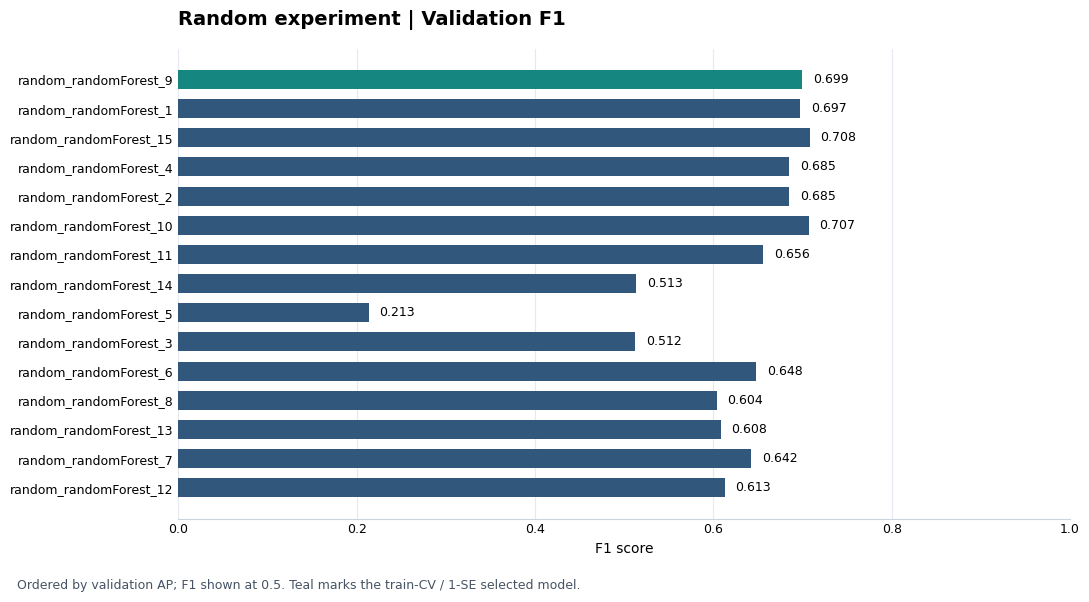

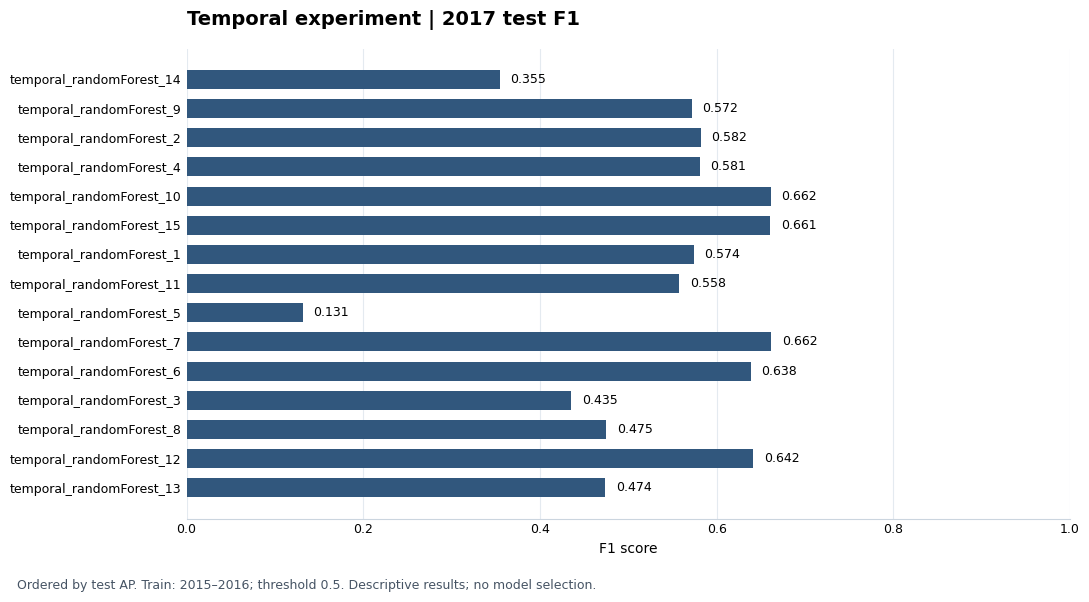

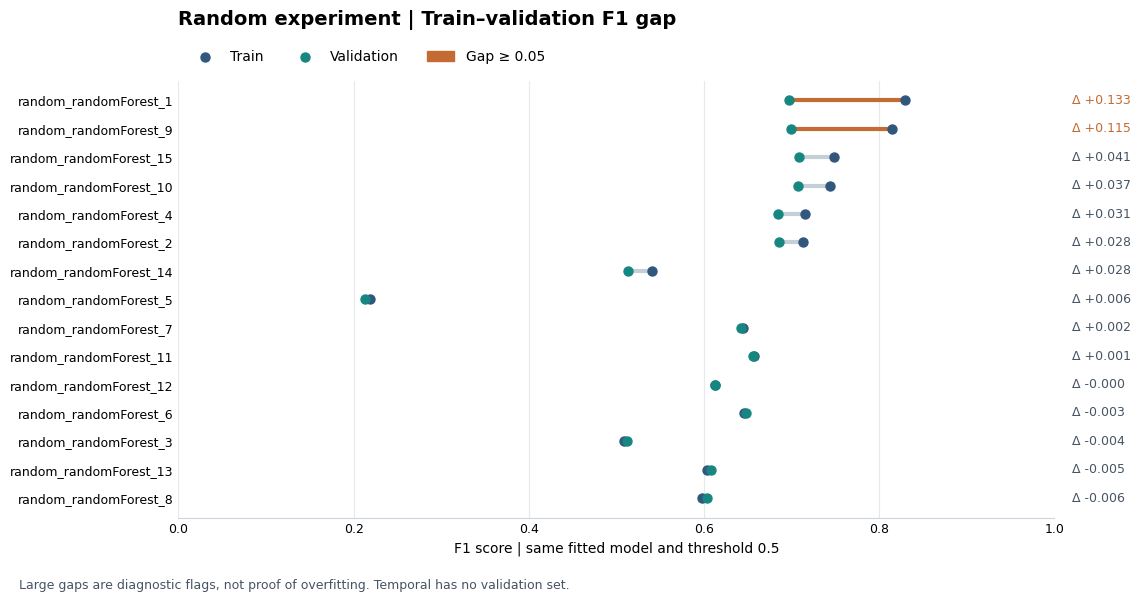

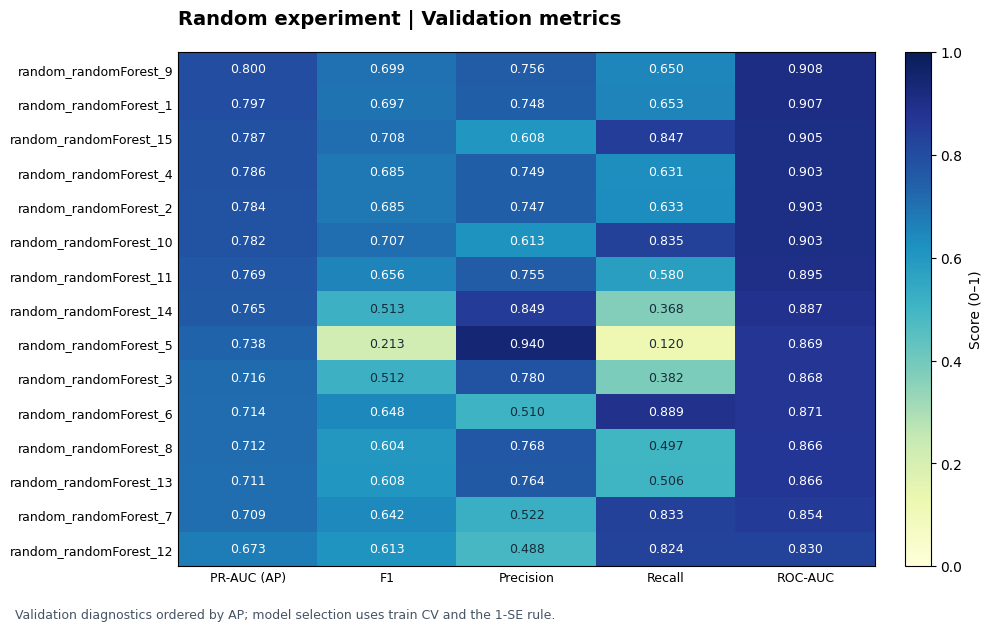

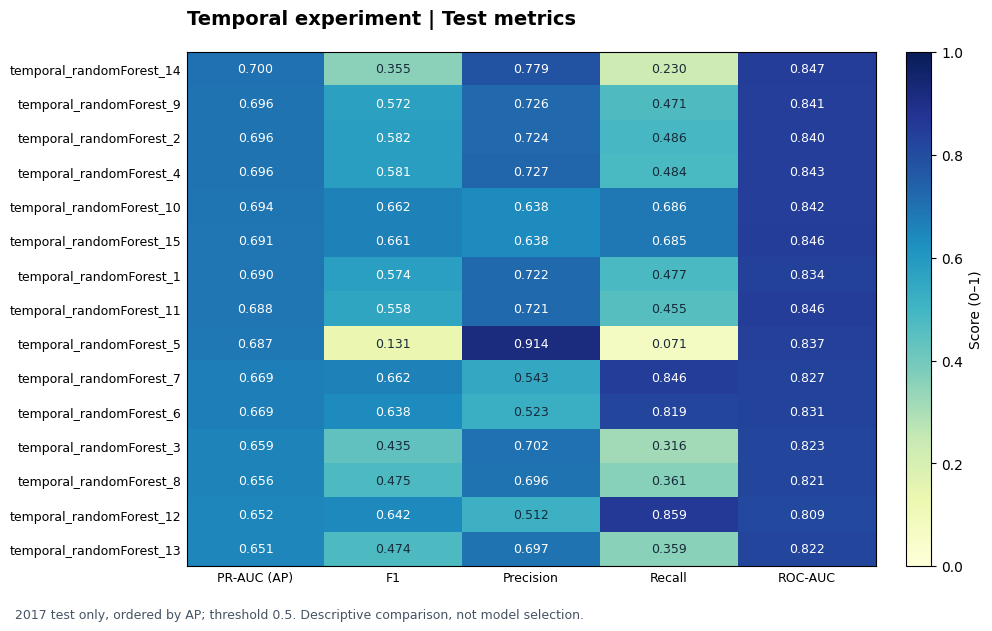

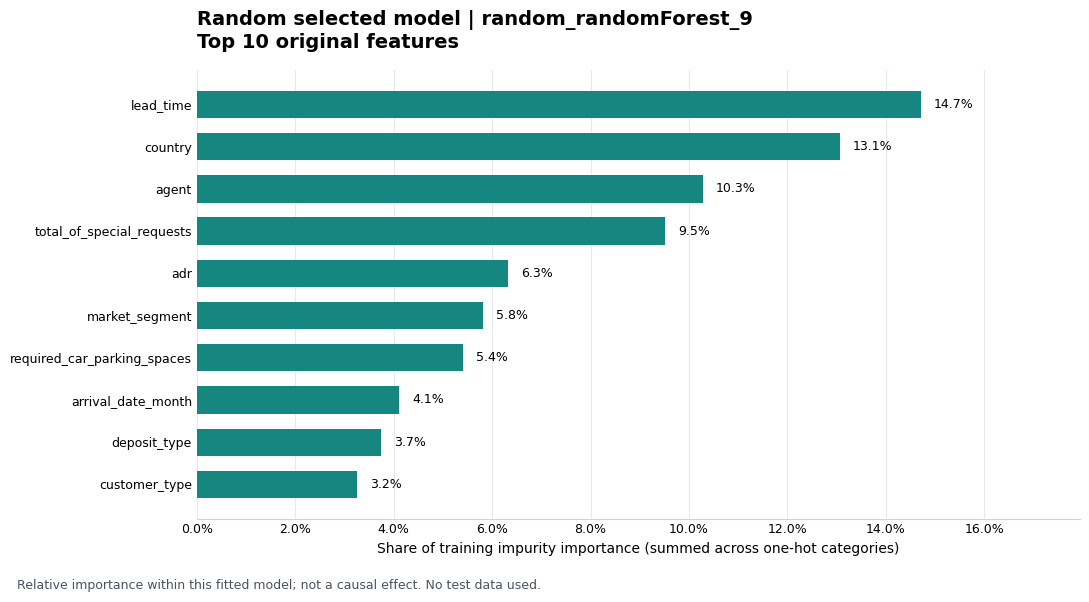

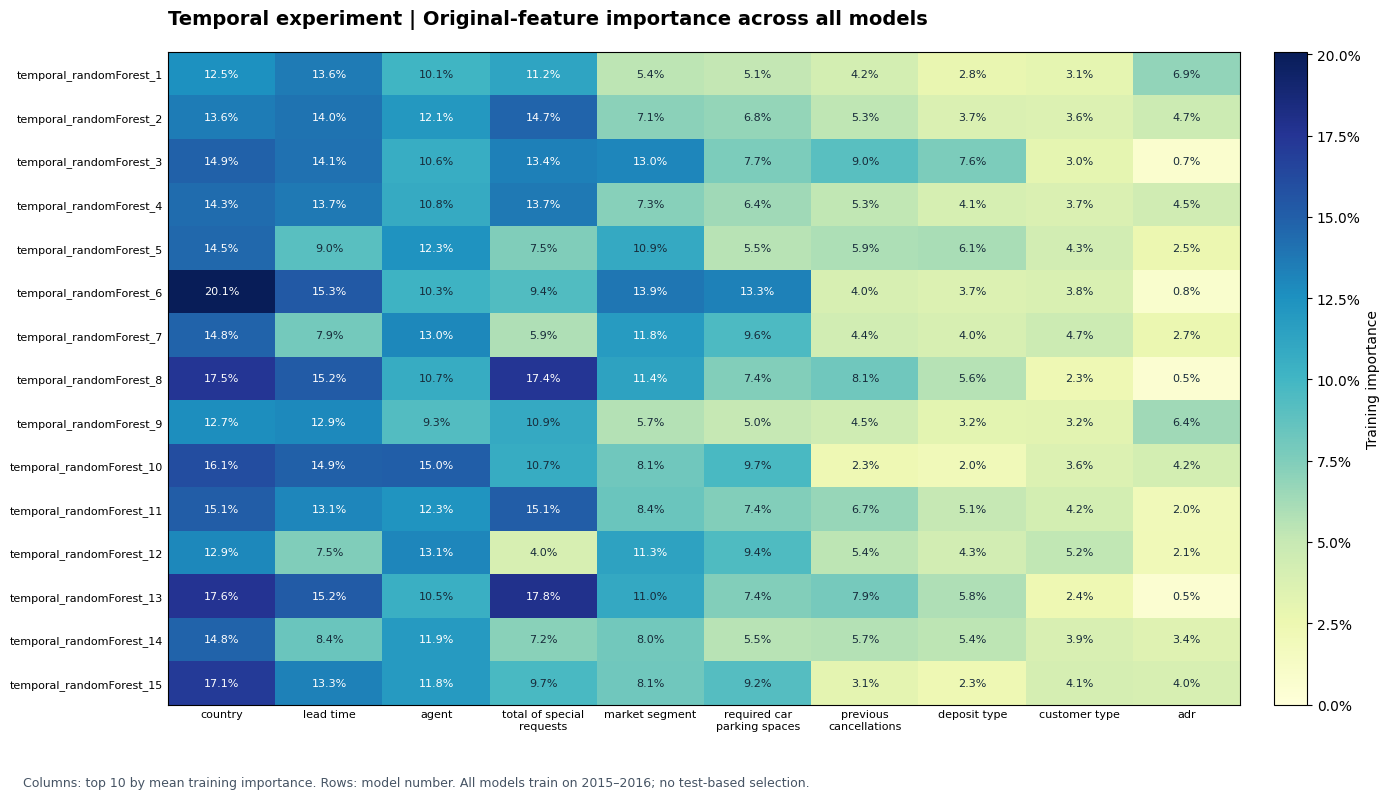

Saved 7 PNG figures for model_results_3.csv:
random_validation_f1_run_3.png
temporal_test_f1_run_3.png
random_train_validation_f1_gap_run_3.png
random_validation_metrics_heatmap_run_3.png
temporal_test_metrics_heatmap_run_3.png
random_selected_top10_feature_importance_run_3.png
temporal_feature_importance_heatmap_run_3.png


In [9]:
run_label = results_path.stem.replace("model_results", "run")
plot_paths = export_result_plots(
    model_results, feature_importances, results_directory, run_label,
    selected_model_name=selection_results["random"]["model_name"],
    show=True, f1_gap=OVERFIT_F1_GAP,
)
print(f"Saved {len(plot_paths)} PNG figures for {results_path.name}:")
for path in plot_paths.values():
    print(path.name)
